## Q-Vectors --> SEMD --> dimension

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import energyflow as ef
from energyflow.utils import gen_massless_phase_space
from energyflow import EFPSet
import os
import glob
import time
from RegressFunctions import *
from RestrictedEFPs import efps_chunked
from PhysicsFunctions import *
from scipy.special import gammaln, digamma, polygamma, zeta
from scipy.interpolate import UnivariateSpline
from scipy.optimize import brentq

os.makedirs('figures', exist_ok=True)

## Import Q-Vectors

In [2]:
labels = {'Z': r'$Z\to q\bar q$', 
          'Z1': r'$Z\to q\bar q$, 1 splitting', 
        #   'Z2': r'$Z\to q\bar q$, 2 splittings',
        #   'Z3': r'$Z\to q\bar q$, 3 splittings', 'Z4': r'$Z\to q\bar q$, 4 splittings',
          'Z1_500GeV': r'$Z\to q\bar q$, 1 splitting, $\sqrt{s} = 500$ GeV', 
          'Z1_1TeV': r'$Z\to q\bar q$, 1 splitting, $\sqrt{s} = 1$ TeV',
          'Z1_fix08': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.08$',
          'Z1_fix12': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.12$',
          'Z1_fix16': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.16$',
          }

In [3]:
#########################################################
### Load features (computed in make_features.ipynb)
#########################################################

QVC_sets = {k: np.load(f'features/QVEC_nq2048_{k}.npy', mmap_mode='r') for k in labels if os.path.exists(f'features/QVEC_nq2048_{k}.npy')}
print('Qvc:', {k: v.shape for k, v in QVC_sets.items()}, '  missing:', [k for k in labels if k not in QVC_sets])

Qvc: {'Z': (100000, 2048), 'Z1': (99387, 2048), 'Z1_500GeV': (100000, 2048), 'Z1_1TeV': (100000, 2048), 'Z1_fix08': (73394, 2048), 'Z1_fix12': (86070, 2048), 'Z1_fix16': (92872, 2048)}   missing: []


## SEMD 

In [6]:
def semd_matrix(Q, dev=None):  
    dev = dev or ('cuda' if torch.cuda.is_available() else 'cpu')
    Q = torch.as_tensor(np.asarray(Q), dtype=torch.float64, device=dev)
    return torch.cdist(Q, Q)**2 / Q.shape[1]

def N_of_Q(S, Q):
    return ((S < Q**2).sum(1) - 1).double().mean().item()       # per-event count of neighbours within Q (minus self)

In [ ]:
Qs = np.logspace(-2, 0, 50)
M = 5_000
Ns, Nm, Ds, Qm = {}, {}, {}, {}
# minNs = {'Z': 0.3, 'Z08': 3e3, 'Z12': 2e3, 'Z16': 1e3, 'Z1': 0.3, 'Z2': 0.3, 'Z3': 0.3, 
#         'Z500GeV': 0.3, 'Z1TeV': 0.3, 'Z2TeV': 0.3,  'Z4TeV': 0.3, 'Z8TeV': 0.3, 'Z16TeV': 0.3, 'Z32TeV': 0.3, 
#         'Z1mine': 0.3, 'Z1 500 GeV': 0.3, 'Z1 1 TeV': 0.3, 'Zuu_1_fix': 0.3, 'Zuu_1_fix_me': 0.3, 
#         'Z1 fix08': 0.3, 'Z1 fix12': 0.3, 'Z1 fix16': 0.3}
# Distance from Born
Qborn = np.r_[np.zeros(1024), np.full(1024, np.pi)]
Nb, Db, Qb = {}, {}, {}
North, Nfull, Dorth, Dfull = {}, {}, {}, {}

for key in labels:
    S = semd_matrix(QVC_sets[key][:M])
    Ns[key] = np.array([N_of_Q(S, Q) for Q in Qs])
    ok = Ns[key] > 0.3 # minNs[key]                  
    Nm[key] = Ns[key][ok]        
    Qm[key] = Qs[ok]
    Ds[key] = np.gradient(np.log(Ns[key][ok]), np.log(Qm[key]))
    ### Define V ### 
    V = QVC_sets[key][:M] - Qborn 
    ###### Born-Referenced ####
    d_born = np.linalg.norm(QVC_sets[key] - Qborn , axis=1)/np.sqrt(2048)   
    Nb[key] = np.array([(d_born < Q).sum() for Q in Qs])
    okb = Nb[key] > 10
    Qb[key] = Qs[okb]
    Db[key] = np.gradient(np.log(Nb[key][okb]), np.log(Qb[key]))   
    ###### drop cross term #####
    db = np.linalg.norm(V, axis=1)/np.sqrt(2048)       # |v_A| = 2 sqrt(tau_A), one per event
    d2 = torch.as_tensor(db**2, device=S.device);  D2orth = d2[:, None] + d2[None, :];  D2orth.fill_diagonal_(float('inf'))
    North[key] = np.array([(D2orth < Q**2).sum(1).double().mean().item() for Q in Qs])
    Dorth[key]  = np.gradient(np.log(North[key]), np.log(Qs))
    print(f'done {key}')

/var/folders/3b/1lt3qrpn635524qxcctqlg040000gn/T/ipykernel_27049/2280416550.py:32: RuntimeWarning: divide by zero encountered in log
  Dorth[key]  = np.gradient(np.log(North[key]), np.log(Qs))
/Users/stevenferrante/mambaforge/lib/python3.10/site-packages/numpy/lib/function_base.py:1250: RuntimeWarning: invalid value encountered in multiply
  out[tuple(slice1)] = a * f[tuple(slice2)] + b * f[tuple(slice3)] + c * f[tuple(slice4)]
/Users/stevenferrante/mambaforge/lib/python3.10/site-packages/numpy/lib/function_base.py:1250: RuntimeWarning: invalid value encountered in add
  out[tuple(slice1)] = a * f[tuple(slice2)] + b * f[tuple(slice3)] + c * f[tuple(slice4)]
/Users/stevenferrante/mambaforge/lib/python3.10/site-packages/numpy/lib/function_base.py:1259: RuntimeWarning: invalid value encountered in scalar subtract
  out[tuple(slice1)] = (f[tuple(slice2)] - f[tuple(slice3)]) / dx_0


done Z
done Z1
done Z1_500GeV
done Z1_1TeV
done Z1_fix08
done Z1_fix12
done Z1_fix16


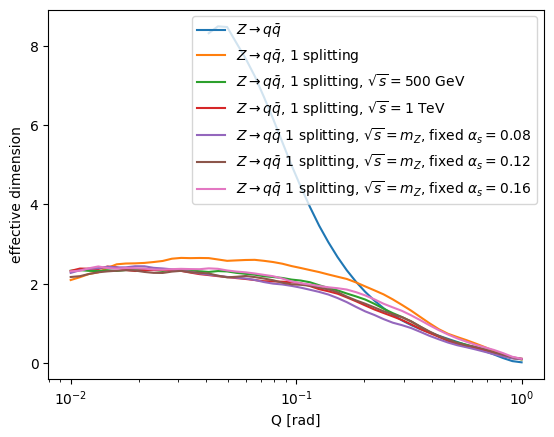

In [11]:
for key in labels:
    plt.semilogx(Qm[key], Ds[key], label=labels[key])
plt.xlabel('Q [rad]'); plt.ylabel('effective dimension'); plt.legend()

## Analytic Result

In [18]:
def onesplit_curves(Qs, a_mz=0.1365, sqrtS=91.19, ptmin=0.5, nw=100, nz=100,
                    running=True, fullP=True, born_pairs=False, exactME=True):
    """One-emission soft-collinear curves: Sigma (orange), N_nocross (green), N_pair (blue).
       Sudakov in kt (Pythia's first emission);  fullP: (1+(1-x)^2)/2, x=2z.
       born_pairs=False conditions on exactly one emission (matches the 1-splitting sample)."""
    CF = 4/3;  beta0 = 23/(12*np.pi)
    alpha = (lambda mu: np.minimum(a_mz/(1 + beta0*a_mz*np.log(mu**2/91.19**2)), 2.0)) if running else (lambda mu: a_mz + 0*mu)
    ### Boundaries of z, w, ...  ### 
    eps = ptmin/sqrtS;   
################### Boundaries of phase space ###################
    zmin, zmax = eps/2, 0.5 - eps/2                                    # z_P in [pT/m, 1-pT/m] at pT = ptmin
    wlo = lambda z: eps/np.sqrt(z*(1 - 2*z)/2)                         # pT = z(1-2z) theta sqrtS >= ptmin
    whi = lambda z: 2*np.minimum(z, 0.5 - z)/np.sqrt(z*(1 - 2*z)/2)    # pT <= 2 sqrtS min(z, 1/2-z)
################### Grid in log w, log z ########################
    w = np.exp(np.linspace(np.log(wlo(0.25)*0.999), np.log(whi(0.25)), nw))   # z=1/4 is where wlo is lowest and whi is highest
    lw = np.log(w);  
    dlw = np.gradient(lw)
    z = np.exp(np.linspace(np.log(zmin), np.log(zmax), nz));  
    dlz = np.gradient(np.log(z))
    mask = (w[:, None] > wlo(z)[None, :]) & (w[:, None] < whi(z)[None, :])
################### pT ... Pythia's ordering variable ##############
    kt = w[:, None]*np.sqrt(z[None, :]*(1 - 2*z[None, :])/2)*sqrtS
################### Splitting Function (or MatrixElement) ##############
    Pz = (1 + (1 - 2*z)**2)/2 if fullP else np.ones_like(z)                                         
    if exactME:                                                                           # Z->qqg ME on the Dalitz plane, w^2 = 4 tau
        x2 = 1 - w[:, None]**2/4;  x1 = 1 + w[:, None]**2/4 - 2*z[None, :]                 # recoiler, radiator fractions
        K = (x1**2 + x2**2)/np.clip((1 - x1)*(1 - x2), 1e-12, None)*z[None, :]*w[:, None]**2/4   # -> Pz in the soft-collinear limit
        mask = mask & (w[:, None]**2 <= 4*np.minimum(z, 1 - 2*z)[None, :])                 # recoiler is the hardest parton
    else:
        K = Pz[None, :]
    Awz = 4*CF/np.pi*alpha(kt)*K*mask
###################
    k = np.exp(np.linspace(np.log(ptmin), np.log(sqrtS/2), 600));  lk = np.log(k)
    Ak = 4*CF/np.pi*alpha(k)[:, None]*Pz[None, :]*(np.minimum(z, 0.5 - z)[None, :] > k[:, None]/(2*sqrtS))
###################
    Lk = (Ak*dlz[None, :]).sum(1)
    Rk = np.concatenate([np.cumsum((0.5*(Lk[1:] + Lk[:-1])*np.diff(lk))[::-1])[::-1], [0]])
    sud = np.exp(-np.interp(np.log(np.clip(kt, k[0], k[-1])), lk, Rk))
    rho = Awz*sud      
    P0 = 1 - np.sum(rho*dlw[:, None]*dlz[None, :])  
    if not born_pairs: rho /= (1 - P0);  P0 = 0.0
    rho_w = (rho*dlz[None, :]).sum(1)
    Sig = P0 + np.concatenate([[0], np.cumsum(0.5*(rho_w[1:] + rho_w[:-1])*np.diff(lw))])        # Sigma(w)
    G2 = np.cumsum(rho*dlw[:, None], axis=0) - 0.5*rho*dlw[:, None]                              # G(w, z) = ∫ rho dln w'
    Gof = lambda x, j: np.interp(np.log(np.clip(x, w[0], w[-1])), lw, G2[:, j])
    Sof = lambda x: np.where(x < w[0], P0, np.interp(np.log(np.clip(x, w[0], w[-1])), lw, Sig))
    wA, zA, zB = w[:, None, None], z[None, :, None], z[None, None, :]
    # c = np.sqrt(np.minimum(zA, zB)/np.maximum(zA, zB))                                           # old cos(v_A, v_B)
######################
    lo = z < 0.25;  L2 = np.where(lo, z, 0.5 - z)                                        # 3-block small-angle shape, blocks sorted by angle
    b = np.stack([0.5 - z + 2*z**2, 0.5 + 0*z, 0.5 + L2]);  e = np.stack([0.5 + 0*z, 0.5 + L2, 1 + 0*z])
    h = np.stack([1 + 0*z, np.where(lo, -(1 - 2*z), -2*z), np.where(lo, -2*z, -(1 - 2*z))])
    ov = sum(h[i][:, None]*h[j][None, :]*np.clip(np.minimum(e[i][:, None], e[j][None, :]) - np.maximum(b[i][:, None], b[j][None, :]), 0, None) for i in range(3) for j in range(3))
    c = np.clip(ov/np.sqrt(np.outer(2*z*(1 - 2*z), 2*z*(1 - 2*z))), 0, 1)[None, :, :]   # g(z_a, z_b); soft limit sqrt(z</z>)
######################
    weightA = (rho*dlw[:, None]*dlz[None, :])[:, :, None]
    Sigma, Nno, Npair = [], [], []
    for Q in Qs:
        Sigma.append(Sof(Q))
        Nno.append(P0*Sof(Q) + np.sum(weightA[:, :, 0]*Sof(np.sqrt(np.clip(Q**2 - w[:, None]**2, 0, None)))))   # green
        disc = Q**2 - wA**2*(1 - c**2);  ok = disc > 0;  root = np.sqrt(np.where(ok, disc, 0))
        wm, wp = np.maximum(wA*c - root, wlo(zB)), np.minimum(wA*c + root, whi(zB))
        inner = np.stack([Gof(wp[:, :, j], j) - Gof(wm[:, :, j], j) for j in range(nz)], axis=2)
        Npair.append(P0**2 + 2*P0*(Sof(Q) - P0) + np.sum(weightA*np.clip(inner, 0, None)*ok*dlz[None, None, :]))   # blue
    return np.array(Sigma), np.array(Nno), np.array(Npair)


In [19]:
Qa = np.logspace(-2, 0, 40)
dima = lambda N: np.gradient(np.log(N), np.log(Qa))

settings = {'Z1':        dict(),
            'Z1_500GeV': dict(sqrtS=500),
            'Z1_1TeV':   dict(sqrtS=1000),
            'Z1_fix08':  dict(a_mz=0.08, running=False),
            'Z1_fix12':  dict(a_mz=0.12, running=False),
            'Z1_fix16':  dict(a_mz=0.16, running=False)}

Np = {key: onesplit_curves(Qa, **kw)[2] for key, kw in settings.items() if key in labels}

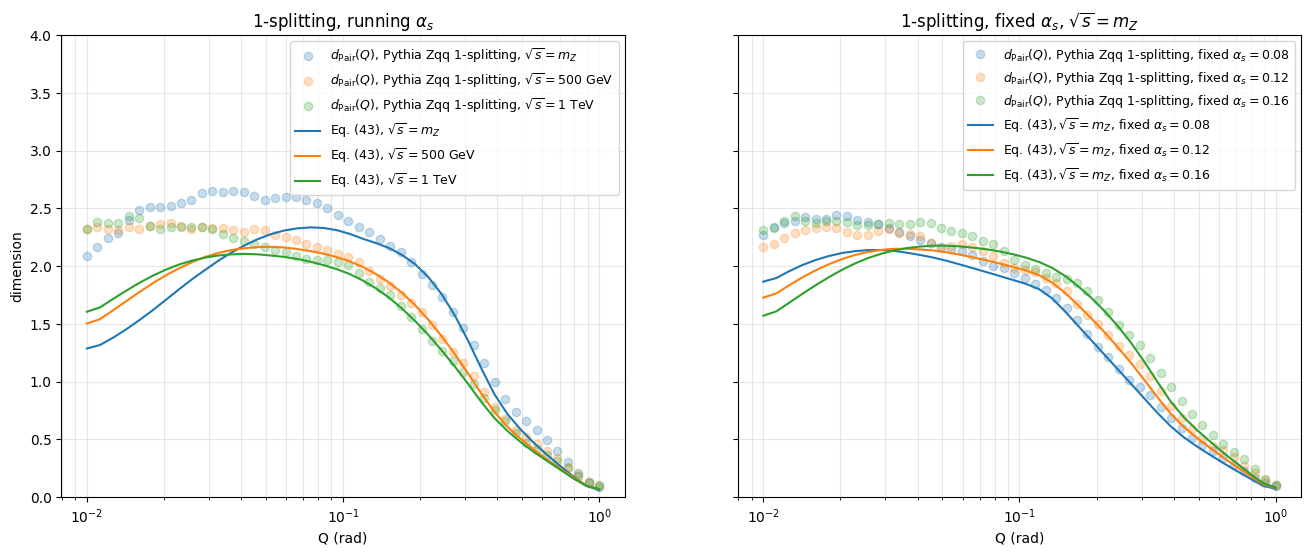

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# left: energy scan, running alpha_s
ax1.semilogx(Qm['Z1'], Ds['Z1'], 'o', color='C0', alpha=0.25, label=r'$d_\text{Pair}(Q)$, Pythia Zqq 1-splitting, $\sqrt{s} = m_Z$')
ax1.semilogx(Qm['Z1_500GeV'], Ds['Z1_500GeV'], 'o', color='C1', alpha=0.25, label=r'$d_\text{Pair}(Q)$, Pythia Zqq 1-splitting, $\sqrt{s} = 500$ GeV');  
ax1.semilogx(Qm['Z1_1TeV'], Ds['Z1_1TeV'], 'o', color='C2', alpha=0.25, label=r'$d_\text{Pair}(Q)$, Pythia Zqq 1-splitting, $\sqrt{s} = 1$ TeV');  
ax1.semilogx(Qa, dima(Np['Z1']), '-', color='C0', label=r'Eq. (43), $\sqrt{s} = m_Z$')
ax1.semilogx(Qa, dima(Np['Z1_500GeV']), '-', color='C1', label=r'Eq. (43), $\sqrt{s} = 500$ GeV')
ax1.semilogx(Qa, dima(Np['Z1_1TeV']), '-', color='C2', label=r'Eq. (43), $\sqrt{s} = 1$ TeV')
ax1.set_title(r'1-splitting, running $\alpha_s$'); ax1.set_xlabel('Q (rad)'); ax1.set_ylabel('dimension')
ax1.set_ylim(0, 4); ax1.legend(fontsize=9); ax1.grid(True, which='both', alpha=0.3)

# right: fixed alpha_s at mZ
ax2.semilogx(Qm['Z1_fix08'], Ds['Z1_fix08'], 'o', color='C0', alpha=0.25, label=r'$d_\text{Pair}(Q)$, Pythia Zqq 1-splitting, fixed $\alpha_s = 0.08$'); 
ax2.semilogx(Qm['Z1_fix12'], Ds['Z1_fix12'], 'o', color='C1', alpha=0.25, label=r'$d_\text{Pair}(Q)$, Pythia Zqq 1-splitting, fixed $\alpha_s = 0.12$'); 
ax2.semilogx(Qm['Z1_fix16'], Ds['Z1_fix16'], 'o', color='C2', alpha=0.25, label=r'$d_\text{Pair}(Q)$, Pythia Zqq 1-splitting, fixed $\alpha_s = 0.16$'); 
ax2.semilogx(Qa, dima(Np['Z1_fix08']), '-', color='C0', label=r'Eq. (43)$, \sqrt{s} = m_Z$, fixed $\alpha_s = 0.08$')
ax2.semilogx(Qa, dima(Np['Z1_fix12']), '-', color='C1', label=r'Eq. (43)$, \sqrt{s} = m_Z$, fixed $\alpha_s = 0.12$')
ax2.semilogx(Qa, dima(Np['Z1_fix16']), '-', color='C2', label=r'Eq. (43)$, \sqrt{s} = m_Z$, fixed $\alpha_s = 0.16$')
ax2.set_title(r'1-splitting, fixed $\alpha_s$, $\sqrt{s} = m_Z$'); ax2.set_xlabel('Q (rad)')
ax2.legend(fontsize=9); ax2.grid(True, which='both', alpha=0.3)

## Reconstructed Spectra 

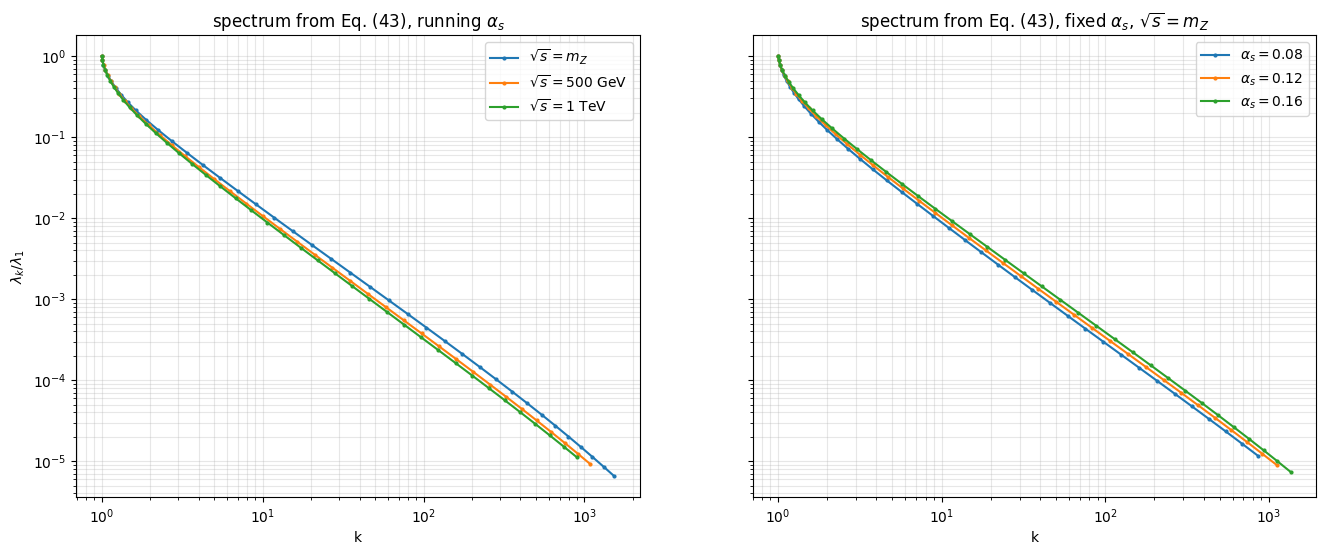

In [24]:
def spectrum_from_N(N, dmin=0.05):
    """λ(k) ∝ exp(-∫ α dln k) with α = 1 + 1/d(Q) and k = 1/N_pair(Q) (one patch = the fraction of events within Q)."""
    d = dima(N);  m = d > dmin                                   # drop the saturated end (d -> 0 makes alpha blow up)
    k, a = (1/N[m])[::-1], (1 + 1/d[m])[::-1]                   # sort by increasing k, i.e. decreasing Q
    lam = np.exp(-np.concatenate([[0], np.cumsum(0.5*(a[1:] + a[:-1])*np.diff(np.log(k)))]))
    return k, lam

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

k, lam = spectrum_from_N(Np['Z1']);        ax1.loglog(k, lam, 'o-', color='C0', markersize=2, label=r'$\sqrt{s} = m_Z$')
k, lam = spectrum_from_N(Np['Z1_500GeV']); ax1.loglog(k, lam, 'o-', color='C1', markersize=2, label=r'$\sqrt{s} = 500$ GeV')
k, lam = spectrum_from_N(Np['Z1_1TeV']);   ax1.loglog(k, lam, 'o-', color='C2', markersize=2, label=r'$\sqrt{s} = 1$ TeV')
ax1.set_title(r'spectrum from Eq. (43), running $\alpha_s$'); ax1.set_xlabel('k'); ax1.set_ylabel(r'$\lambda_k/\lambda_1$')
ax1.legend(); ax1.grid(True, which='both', alpha=0.3)

k, lam = spectrum_from_N(Np['Z1_fix08']);  ax2.loglog(k, lam, 'o-', color='C0', markersize=2, label=r'$\alpha_s = 0.08$')
k, lam = spectrum_from_N(Np['Z1_fix12']);  ax2.loglog(k, lam, 'o-', color='C1', markersize=2, label=r'$\alpha_s = 0.12$')
k, lam = spectrum_from_N(Np['Z1_fix16']);  ax2.loglog(k, lam, 'o-', color='C2', markersize=2, label=r'$\alpha_s = 0.16$')
ax2.set_title(r'spectrum from Eq. (43), fixed $\alpha_s$, $\sqrt{s} = m_Z$'); ax2.set_xlabel('k')
ax2.legend(); ax2.grid(True, which='both', alpha=0.3)